# Signal exploration: waveforms, spectra and bearing-frequency hypotheses

The original investigation moved from waveform inspection to FFTs, filtered Hilbert envelopes and bearing-frequency rules (E1–48 and E108–139). This notebook restores the computational methods and the reasons their apparent diagnostic value needs qualification.

Run cells in order. Defaults use a clearly labeled synthetic amplitude-modulated carrier and saved historical observations. They require no recordings and perform no classification experiment or model training. Original cell references count all notebook cells, not execution numbers. See the [experiment map](../docs/exploration.md) and [public evidence extract](../results/historical/signal_exploration_evidence.json).

In [1]:
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/cwru_bearing').is_dir()), None)
if REPO is None:
    raise RuntimeError('Open this notebook from the checkout or its notebooks directory.')
sys.path.insert(0, str(REPO / 'src'))
from cwru_bearing.exploration import (
    fft_spectrum, bandpass_signal, hilbert_envelope, envelope_spectrum,
    bearing_frequencies, frequency_rule, shaft_spaced_pairs,
)
evidence = json.loads((REPO / 'results/historical/signal_exploration_evidence.json').read_text(encoding='utf-8'))


## 1. Inspect the waveform before interpreting its spectrum

An amplitude-modulated carrier separates a high-frequency oscillation from its slower envelope. Here the carrier is 3 kHz and the modulation is 120 Hz at 12 kHz sampling. This constructed signal illustrates processing behavior; it is not a simulated bearing diagnosis or CWRU finding.

E6–7 plotted healthy record 97 under a 12 kHz label. Its documented acquisition rate is 48 kHz: 1,200 samples span 0.025 s, although the old axes showed 0.1 s. Rate labels must therefore be distinguished from acquisition rates.

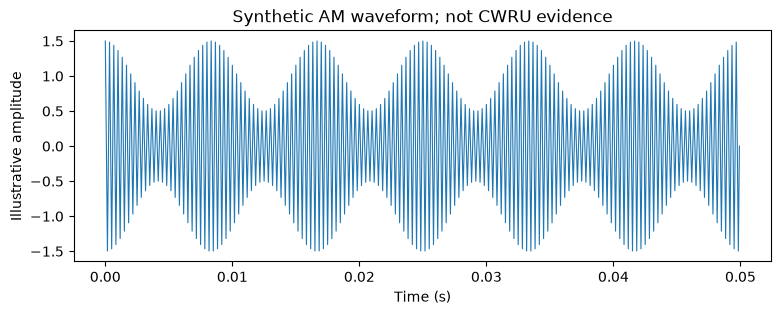

In [2]:
fs = 12000
sample_time = np.arange(fs) / fs
synthetic_envelope = 1 + 0.5 * np.cos(2 * np.pi * 120 * sample_time)
signal = synthetic_envelope * np.cos(2 * np.pi * 3000 * sample_time)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(sample_time[:600], signal[:600], linewidth=0.8)
ax.set(xlabel='Time (s)', ylabel='Illustrative amplitude', title='Synthetic AM waveform; not CWRU evidence')
plt.show()

## 2. Raw FFT versus mean-removed Hann spectrum

E8–10 used `abs(rfft(x))/N` without removing the mean. E13–16 removed the mean, applied the symmetric `np.hanning(N)` window, and used `2*abs(rfft(x*w))/sum(w)`. These are amplitude spectra, not power spectral densities. The historical Hann convention doubles every bin, including DC and Nyquist; the implementation retains that convention rather than silently changing it. Peak locations alone do not identify the damaged component.

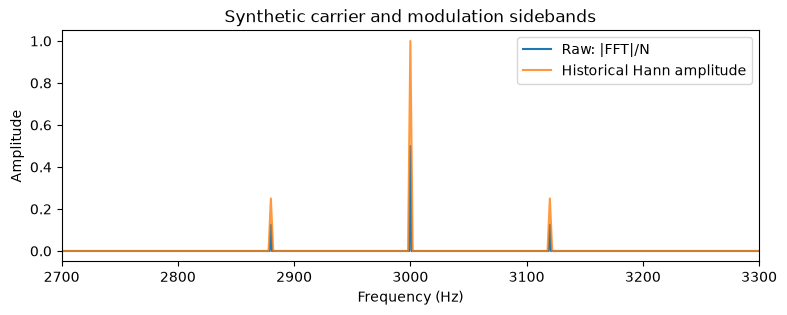

In [3]:
frequency, raw_amplitude = fft_spectrum(signal, fs, windowed=False)
_, hann_amplitude = fft_spectrum(signal, fs)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(frequency, raw_amplitude, label='Raw: |FFT|/N')
ax.plot(frequency, hann_amplitude, label='Historical Hann amplitude', alpha=0.8)
ax.set(xlim=(2700, 3300), xlabel='Frequency (Hz)', ylabel='Amplitude', title='Synthetic carrier and modulation sidebands')
ax.legend()
plt.show()

## 3. Bandpass filtering and the Hilbert envelope

E34–35 applied a fourth-order Butterworth bandpass at nominal 2–4 kHz, forward/backward `filtfilt`, Hilbert magnitude, envelope demeaning, and a Hann FFT. E108 additionally removed the signal mean before filtering. Both variants remain explicit in the API. No edge trimming or alternate filter representation has been introduced.

The synthetic envelope peak should appear near 120 Hz. Finite-record filter and Hilbert edge effects remain. Applying the historical 12 kHz filter design to a 48 kHz healthy recording selects a physical band near 8–16 kHz, so healthy/fault envelope comparisons are acquisition-confounded.

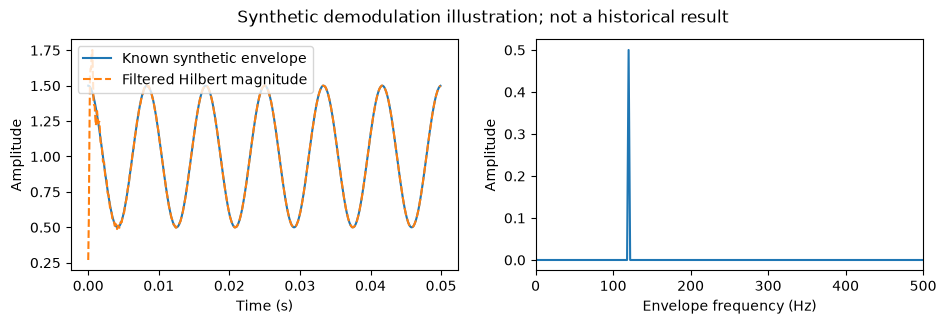

In [4]:
filtered = bandpass_signal(signal, fs)
recovered_envelope = hilbert_envelope(filtered)
envelope_frequency, envelope_amplitude = envelope_spectrum(signal, fs)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(sample_time[:600], synthetic_envelope[:600], label='Known synthetic envelope')
axes[0].plot(sample_time[:600], recovered_envelope[:600], '--', label='Filtered Hilbert magnitude')
axes[0].set(xlabel='Time (s)', ylabel='Amplitude')
axes[0].legend()
axes[1].plot(envelope_frequency, envelope_amplitude)
axes[1].set(xlim=(0, 500), xlabel='Envelope frequency (Hz)', ylabel='Amplitude')
fig.suptitle('Synthetic demodulation illustration; not a historical result')
plt.show()

## 4. Bearing characteristic frequencies and naming conventions

E17/E75 multiplied shaft speed (`rpm/60`) by 5.4152 (BPFI, inner race), 3.5848 (BPFO, outer race), 4.7135 (historically labeled BSF), and 0.39828 (FTF, cage). These are fixed drive-end coefficients, not newly estimated geometry or a universal bearing model.

The [CWRU bearing table](https://engineering.case.edu/bearingdatacenter/bearing-information) labels 4.7135 as the **rolling-element defect multiplier**. The historical `BSF` symbol is retained. Using the standard fundamental ball-spin formula with CWRU's rounded geometry and zero contact angle gives a multiplier near 2.3567, about half this value. Thus the old symbol must not be presented as unqualified fundamental ball spin. Nothing here halves the historical rule's targets.

RPM errors, slip, approximate geometry, frequency resolution and processing-rate errors all affect peak alignment. A nearby maximum is evidence to investigate, not proof of a fault.

In [5]:
targets = bearing_frequencies(1796)
display(pd.DataFrame({'Historical target': list(targets), 'Frequency (Hz)': list(targets.values())}))
print('Saved historical E17 output:')
print(evidence['outputs']['17'])

,Historical target,Frequency (Hz)
0,shaft,29.933333
1,BPFI,162.094987
2,BPFO,107.305013
3,BSF,141.090767
4,FTF,11.921848


Saved historical E17 output:
Shaft Frequency: 29.93 Hz
BPFI: 162.09 Hz
BPFO: 107.31 Hz
BSF: 141.09 Hz
FTF: 11.92 Hz



## 5. What the original envelope observations support

E37–39 compared record 105 peaks near the first three BPFI harmonics. E113–116 repeated local searches on .014-inch fault records. The following is the saved E113 observation, not output recomputed from raw data. E36 initially reused the healthy-record RPM for a fault overlay; E38–39 then used the fault RPM. The reusable calculations require an explicit RPM.

In [6]:
print(evidence['outputs']['113'])

1x BPFI | Theoretical: 162.09 Hz | Measured: 162.01 Hz | Difference: -0.09 Hz | Amplitude: 0.09469
2x BPFI | Theoretical: 324.19 Hz | Measured: 324.02 Hz | Difference: -0.17 Hz | Amplitude: 0.03380
3x BPFI | Theoretical: 486.28 Hz | Measured: 486.12 Hz | Difference: -0.16 Hz | Amplitude: 0.01048



## 6. Frequency-family rules: useful hypotheses, limited evidence

E117–121 summed the maximum amplitude within ±2 Hz of each of three harmonics. E122–127 instead summed squared amplitude bins within ±3 Hz and normalized the three family sums by their total plus `1e-12`. Those bin sums omit frequency-bin width and are not integrated physical energy. The ratios are neither class probabilities nor whole-spectrum energy fractions.

Both rules select the largest family among InnerRace, OuterRace and Ball. They have no healthy/reject class. Ties, including all-zero scores, select InnerRace by historical insertion order. The cell below merely demonstrates the API on the synthetic spectrum; its returned label has no bearing-diagnosis meaning.

In [7]:
for method in ['peak', 'band']:
    label, scores = frequency_rule(envelope_frequency, envelope_amplitude, 1796, method)
    print(f'Synthetic API demonstration ({method}); arbitrary fault-family label: {label}')
    display(pd.Series(scores, name='Synthetic score').to_frame())
print('Saved E128 summary on inspected historical fault recordings:')
print(evidence['outputs']['128'])

Synthetic API demonstration (peak); arbitrary fault-family label: OuterRace


,Synthetic score
BPFI_score,2.810884e-08
BPFO_score,3.553686e-07
BSF_score,1.085066e-07


Synthetic API demonstration (band); arbitrary fault-family label: OuterRace


,Synthetic score
BPFI_band_score,3.486700e-15
BPFO_band_score,5.283654e-13
BSF_band_score,5.319246e-14
BPFI_ratio,2.199749e-03
BPFO_ratio,3.333442e-01
BSF_ratio,3.355897e-02


Saved E128 summary on inspected historical fault recordings:
Band-score accuracy: 0.6666666666666666

Correct by class:
            sum  count  mean
true_label                  
Ball          4      8   0.5
InnerRace     8      8   1.0
OuterRace     4      8   0.5

Correct by fault size:
            sum  count      mean
fault_size                      
0.007         8     12  0.666667
0.014         8     12  0.666667



E128 reported **16/24** correct for the band-score rule. All 24 faulty recordings (.007 and .014 inch over four loads) were inspected during method development. Healthy records were excluded, and there was no untouched evaluation. This descriptive outcome is preserved as an exploratory result, not a validated classifier. E119 and E129–139 show why record 197 could favor an inner-race family despite an outer-race label; repeated zooming and parameter choices on the same recordings cannot establish generalization.

## 7. Sidebands and shaft-spaced peak pairs

E134 used candidate sidebands at BPFI ± shaft speed. E136 selected peaks in 50–600 Hz with prominence 0.002. E137 examined adjacent spacing, and E139 searched all peak pairs within ±1 Hz of shaft spacing. The illustration below uses constructed peak locations. Many candidate pairs can occur by chance, so spacing alone does not establish modulation or diagnose a component.

In [8]:
from scipy.signal import find_peaks
peak_indices, _ = find_peaks(envelope_amplitude, prominence=0.01)
print('Synthetic detected envelope peaks below 500 Hz:', envelope_frequency[peak_indices][envelope_frequency[peak_indices] < 500])
shaft = targets['shaft']
illustrative_peaks = np.array([100.0, 100.0 + shaft, 100.0 + 2 * shaft, 250.0])
display(pd.DataFrame(shaft_spaced_pairs(illustrative_peaks, 1796)))
print('Candidate sidebands around historical BPFI:', targets['BPFI'] - shaft, targets['BPFI'] + shaft)

Synthetic detected envelope peaks below 500 Hz: [120.]


,peak_1,peak_2,spacing,difference_from_shaft
0,100.000000,129.933333,29.933333,3.552714e-15
1,129.933333,159.866667,29.933333,3.552714e-15


Candidate sidebands around historical BPFI: 132.1616533333333 192.02831999999998


## 8. Optional real-record inspection

Set `CWRU_DATA_ROOT`, then explicitly enable `RUN_RAW`. The comparison below uses the historical nominal 12 kHz processing label for records 97 and 105 and prints their different acquisition durations. It creates no files. To compare physical spectra after acquisition-rate harmonization, define a separate protocol; changing only the axis label does not resample a signal or preserve the filter's physical band.

In [9]:
RUN_RAW = False
if RUN_RAW:
    if not os.environ.get('CWRU_DATA_ROOT'):
        raise RuntimeError('Set CWRU_DATA_ROOT before enabling real-record inspection.')
    from cwru_bearing.data import load_signal
    raw_root = Path(os.environ['CWRU_DATA_ROOT'])
    fig, axes = plt.subplots(2, 3, figsize=(13, 6))
    for row, (record_id, acquisition_rate) in enumerate([(97, 48000), (105, 12000)]):
        raw_signal = load_signal(raw_root, record_id)
        f, a = fft_spectrum(raw_signal, 12000)
        ef, ea = envelope_spectrum(raw_signal, 12000)
        axes[row, 0].plot(np.arange(1200) / 12000, raw_signal[:1200], linewidth=0.6)
        axes[row, 0].set(xlabel='Nominal time at 12 kHz (s)', ylabel='Recorded amplitude', title=f'Record {record_id}')
        axes[row, 1].plot(f, a)
        axes[row, 1].set(xlim=(0, 1200), xlabel='Nominal frequency at 12 kHz (Hz)', ylabel='Hann amplitude')
        axes[row, 2].plot(ef, ea)
        axes[row, 2].set(xlim=(0, 600), xlabel='Nominal envelope frequency (Hz)', ylabel='Hann amplitude')
        print(f'Record {record_id}: 1200 samples span {1200/acquisition_rate:.3f} s at documented acquisition rate.')
    fig.suptitle('Historical nominal-rate inspection; healthy/fault acquisitions differ')
    plt.tight_layout()
    plt.show()
else:
    print('Real-record inspection disabled; synthetic demonstrations and historical extracts only.')

Real-record inspection disabled; synthetic demonstrations and historical extracts only.


## From spectral hypotheses to statistical baselines

The envelope rules motivated examining whether simpler amplitude statistics already separated these selected records. [Notebook 02](02_classical_baselines.ipynb) explains RMS, peak, Pearson kurtosis, crest factor and the three SVM protocols. The later STFT experiments retain time-varying spectral structure rather than treating a handful of harmonic bands as a validated decision rule.

[Project overview](../README.md) | [Next: classical baselines](02_classical_baselines.ipynb)